# Visualization Exercise: Kaggle Data Science Survey 2020

Time to put your skills to work on a **real-world dataset**!

In this notebook you will build publication-ready and stakeholder-ready visualizations from the 2020 Kaggle Data Science Survey, a global snapshot of who data scientists are, what tools they use, and how much they earn.

You will use all three libraries from the intro notebook:

- **Matplotlib** for at least one plot

- **Seaborn** for at least one plot

- **Plotly** for at least one interactive plot

> **Before you start**: run notebook **3_Fetching_the_data.ipynb** first to create `data/kaggle_survey.csv`.

## Learning Objectives

1. Load and explore a real-world survey dataset

2. Prepare data for visualization (clean, aggregate, reshape)

3. Create **explanatory** visualizations that clearly answer specific stakeholder questions

4. Choose the right library and chart type for each question

5. Apply professional formatting (titles, labels, colour, annotations)

## Dataset Overview

The CSV contains responses to 18 survey questions. Here is a reference table:

| Column | Question |
|---|---|
| `age_range` | What is your age? |
| `gender` | What is your gender? |
| `county_residence` | In which country do you currently reside? |
| `highest_education` | Highest level of formal education |
| `latest_job_role` | Current job title |
| `years_of_programming` | Years writing code |
| `programming_language_recommended` | What language would you recommend first? |
| `computing_platforms` | Primary computing platform for data science |
| `years_of_experience` | Years using machine learning methods |
| `size_of_company` | Size of employer |
| `number_of_data_scientists` | Data scientists at your employer |
| `employer_incorporate_ml` | Does your employer use ML methods? |
| `yearly_earnings` | Current yearly compensation (USD) |
| `money_spend_on_cloud` | Spend on ML / cloud services in past 5 years |
| `most_used_data_products` | Primary big data / database product |
| `most_used_bi_tool` | Primary BI tool |
| `primary_tool_data_analysis` | Primary tool for data analysis |


## Setup and Import

In [1]:
# --- Import all required libraries ---
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

print("Libraries ready!")

Libraries ready!


In [2]:
# --- Show Plotly charts as static PNG pictures ---
# Plotly normally embeds the whole chart data in the notebook (megabytes).
# A PNG keeps the saved notebook small. Uses the kaleido package.
# Delete these two lines to get the interactive charts back.
import plotly.io as pio

pio.renderers.default = "png"

In [3]:
# --- Load the Kaggle survey dataset ---
# Run 3_Fetching_the_data.ipynb first if this file does not exist
df = pd.read_csv("data/kaggle_survey.csv")

print(f"Shape: {df.shape}")
df.head()

Shape: (20036, 19)


,id,age_range,gender,county_residence,highest_education,latest_job_role,years_of_programming,programming_language_recommended,computing_platforms,times_tpu_used,years_of_experience,size_of_company,number_of_data_scientists,employer_incorporate_ml,yearly_earnings,money_spend_on_cloud,most_used_data_products,most_used_bi_tool,primary_tool_data_analysis
0,7232,35-39,Man,Colombia,Doctoral degree,Student,5-10 years,Python,"A cloud computing platform (AWS, Azure, GCP, h...",2-5 times,1-2 years,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Basic statistical software (Microsoft Excel, G..."
1,7233,30-34,Man,United States of America,Master’s degree,Data Engineer,5-10 years,Python,A personal computer or laptop,2-5 times,1-2 years,"10,000 or more employees",20+,"We have well established ML methods (i.e., mod...","100,000-124,999","$100,000 or more ($USD)",PostgresSQL,Microsoft Power BI,"Business intelligence software (Salesforce, Ta..."
2,7234,35-39,Man,Argentina,Bachelor’s degree,Software Engineer,10-20 years,R,A personal computer or laptop,Never,I do not use machine learning methods,"1000-9,999 employees",0,No (we do not use ML methods),"15,000-19,999",$0 ($USD),NaN,NaN,"Basic statistical software (Microsoft Excel, G..."
3,7235,30-34,Man,United States of America,Master’s degree,Data Scientist,5-10 years,Python,"A cloud computing platform (AWS, Azure, GCP, h...",2-5 times,3-4 years,250-999 employees,5-9,"We have well established ML methods (i.e., mod...","125,000-149,999","$10,000-$99,999",MySQL,NaN,"Local development environments (RStudio, Jupyt..."
4,7236,30-34,Man,Japan,Master’s degree,Software Engineer,3-5 years,Python,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Getting to Know the Data

Before you visualize, **always explore**. Surprises at this stage save hours later.

Work through the cells below to understand the structure, column types, and distribution of values.

In [4]:
# --- Inspect data types and missing values ---
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20036 entries, 0 to 20035
Data columns (total 19 columns):
 #   Column                            Non-Null Count  Dtype
---  ------                            --------------  -----
 0   id                                20036 non-null  int64
 1   age_range                         20036 non-null  str  
 2   gender                            20036 non-null  str  
 3   county_residence                  20036 non-null  str  
 4   highest_education                 19569 non-null  str  
 5   latest_job_role                   19277 non-null  str  
 6   years_of_programming              19120 non-null  str  
 7   programming_language_recommended  17740 non-null  str  
 8   computing_platforms               16737 non-null  str  
 9   times_tpu_used                    16780 non-null  str  
 10  years_of_experience               16374 non-null  str  
 11  size_of_company                   11403 non-null  str  
 12  number_of_data_scientists         11282 non

In [5]:
# --- Check unique values in key categorical columns ---
for col in ["latest_job_role", "gender", "highest_education"]:
    print(f"\n{col} ({df[col].nunique()} unique values):")
    print(df[col].value_counts().head(10))


latest_job_role (13 unique values):
latest_job_role
Student                      5171
Data Scientist               2676
Software Engineer            1968
Other                        1737
Currently not employed       1652
Data Analyst                 1475
Research Scientist           1174
Machine Learning Engineer    1082
Business Analyst              798
Product/Project Manager       692
Name: count, dtype: int64

gender (5 unique values):
gender
Man                        15789
Woman                       3878
Prefer not to say            263
Prefer to self-describe       54
Nonbinary                     52
Name: count, dtype: int64

highest_education (7 unique values):
highest_education
Master’s degree                                                      7859
Bachelor’s degree                                                    6978
Doctoral degree                                                      2302
Some college/university study without earning a bachelor’s degree    1092
Prof

In [6]:
# --- Check for missing data ---
missing = df.isna().sum().sort_values(ascending=False)
missing[missing > 0]

most_used_bi_tool                   18538
most_used_data_products             16523
money_spend_on_cloud                 9466
yearly_earnings                      9307
employer_incorporate_ml              8906
number_of_data_scientists            8754
size_of_company                      8633
primary_tool_data_analysis           6746
years_of_experience                  3662
computing_platforms                  3299
times_tpu_used                       3256
programming_language_recommended     2296
years_of_programming                  916
latest_job_role                       759
highest_education                     467
dtype: int64

---

## Checkpoint A: Understanding the Data

Answer these before writing any visualization code:

1. How many survey respondents are there in total?

2. How many unique job roles are in the dataset?

3. Which column has the most missing values?

4. What format is the `yearly_earnings` column in, is it ready to plot directly?

5. If you wanted to plot the number of respondents per country, which column would you use?


**My answers** (from the cells above)

1. **20,036 respondents**: `df.shape` gives 20,036 rows, one row per person (the `id` column is unique).
2. **13 job roles**: `df["latest_job_role"].nunique()`. The largest group is "Student" (5,171); 759 people gave no role.
3. **`most_used_bi_tool`**: 18,538 of 20,036 values are missing (93 %). Only some respondents were shown that question.
4. **Not ready to plot:** `yearly_earnings` is text (dtype `str`; older pandas showed `object`). It holds 25 pay bands such as `"10,000-14,999"`, `"$0-999"` or `"> $500,000"`. A computer cannot put text on a number axis, so the Challenge 1 helper turns each band into its lower number.
5. **`county_residence`** (a typo for "country"): `df["county_residence"].value_counts()` counts respondents per country.

---

## Challenge 1: Salary Comparison by Job Role

**Stakeholder question**: *"We want a visual comparison of the yearly compensation of Data Scientists, Data Analysts, and Data Engineers."*

**Chart type suggestion**: Box plot or violin plot (shows distribution, not just average)

**Library suggestion**: Seaborn or Plotly (interactivity helps here)

### Data Preparation

The `yearly_earnings` column contains strings like `'$10,000-$14,999'`. The helper code below converts these to a single integer (the lower bound of the range). You must use `data_compensation` for your plot.

In [7]:
# --- Helper: convert salary strings to integers ---
# Pandas 3.0 note: use .copy() to avoid SettingWithCopyWarning under Copy-on-Write
compensation = df[["latest_job_role", "yearly_earnings"]].copy()
compensation = compensation.dropna()


def get_first_number(x):
    """Extract the lower bound from a salary range string."""
    x = x.split("-")[0]
    x = x.replace(",", "").replace(">", "").replace("$", "").strip()
    return int(x)


# Apply the function to create a clean numeric salary column
compensation["salary_usd"] = compensation["yearly_earnings"].apply(get_first_number)

# Filter to the three roles of interest
roles_of_interest = ["Data Scientist", "Data Analyst", "Data Engineer"]
data_compensation = compensation[
    compensation["latest_job_role"].isin(roles_of_interest)
]

print(f"Rows available: {len(data_compensation)}")
data_compensation.head()

Rows available: 4027


,latest_job_role,yearly_earnings,salary_usd
1,Data Engineer,"100,000-124,999",100000
3,Data Scientist,"125,000-149,999",125000
8,Data Scientist,"70,000-79,999",70000
13,Data Engineer,"90,000-99,999",90000
21,Data Scientist,$0-999,0


                  count     25%      50%      75%      IQR       max
latest_job_role                                                     
Data Analyst     1260.0  1000.0   7500.0  40000.0  39000.0  500000.0
Data Engineer     369.0  5000.0  25000.0  70000.0  65000.0  500000.0
Data Scientist   2398.0  3000.0  25000.0  80000.0  77000.0  500000.0


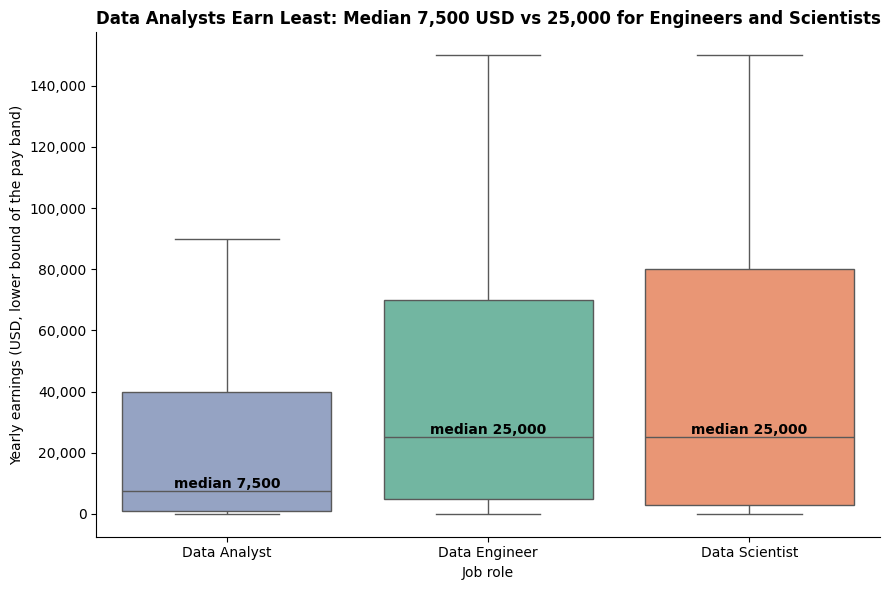

In [8]:
# Create a plot that clearly shows salary distributions for the three roles
# Requirements:
#   - Show the distribution (not just mean), use box, violin, or strip plot
#   - Label axes clearly with units
#   - Add a descriptive title
#   - Use at least one of: Seaborn or Plotly

# --- First the numbers: median and middle 50 % per role ---
summary = data_compensation.groupby("latest_job_role")["salary_usd"].describe()
summary["IQR"] = summary["75%"] - summary["25%"]  # width of the box
print(summary[["count", "25%", "50%", "75%", "IQR", "max"]])

# --- Box plot with Seaborn ---
order = ["Data Analyst", "Data Engineer", "Data Scientist"]  # lowest median first
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(
    data=data_compensation,
    x="latest_job_role",
    y="salary_usd",
    order=order,
    hue="latest_job_role",  # colour per role (legend would repeat the x-axis)
    palette="Set2",
    legend=False,
    showfliers=False,  # hide outlier dots (up to 500,000) so the boxes stay readable
    ax=ax,
)
# Write the median on each box
for i, role in enumerate(order):
    med = data_compensation.loc[data_compensation["latest_job_role"] == role, "salary_usd"].median()
    ax.text(i, med, f"median {med:,.0f}", ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_title(
    "Data Analysts Earn Least: Median 7,500 USD vs 25,000 for Engineers and Scientists",
    fontsize=12,
    fontweight="bold",
)
ax.set_xlabel("Job role")
ax.set_ylabel("Yearly earnings (USD, lower bound of the pay band)")
ax.yaxis.set_major_formatter(lambda v, pos: f"{v:,.0f}")  # 100000 -> 100,000
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What it shows:** the line in each box is the median (the middle person), the box holds the middle 50 % of people, the whiskers show the usual range. Data Analysts have the lowest median (7,500 USD) and the narrowest box. Data Scientists have the widest box (25 % earn 80,000 USD or more). The numbers look low because the survey is global: many answers come from countries with lower salaries. Outlier dots are hidden; in every role a few people report up to 500,000 USD.

---

## Checkpoint B: Before You Move On

Review your Challenge 1 plot:

1. Can a non-technical person understand what the chart shows without reading the code?

2. Are the axes labelled with the variable name AND unit (USD)?

3. Can you see the median AND the spread for each role?

4. Is the title a statement or finding, not just a description?
   - Weak: *'Salary by Job Role'*
   - Strong: *'Data Engineers Tend to Earn More Than Data Analysts'*


**My answers**

1. Yes: the title says the finding in plain words, and the three role names are on the x-axis.
2. Yes: "Yearly earnings (USD, lower bound of the pay band)". It also says honestly that we use the lowest value of each band.
3. Yes: the line inside each box is the median, the box and whiskers show the spread, and the median value is written on each box.
4. Yes: the title is a finding ("Data Analysts Earn Least ..."), not a description.

---

## Challenge 2: Gender Distribution by Country

**Stakeholder question**: *"Show the gender distribution in the top 10 countries by total survey participation. Also show the top 10 countries with the most female participants."*

**This is actually two related plots:**

- **Plot 2a**: Top 10 countries by total respondents, stacked or grouped bar, coloured by gender

- **Plot 2b**: Top 10 countries by female respondents, bar or horizontal bar chart

**Hints**:

- Use `df['county_residence'].value_counts()` to find the top countries

- Filter to only the top 10 before plotting

- For stacked bars in Seaborn, you may need to `pivot` the data first

- For Plotly, `barmode='stack'` or `barmode='group'` handles this automatically

In [9]:
# --- Starter code: find top 10 countries by total participants ---
top_10_countries = df["county_residence"].value_counts().head(10).index.tolist()
print("Top 10 countries:", top_10_countries)

# Filter df to only these countries
df_top10 = df[df["county_residence"].isin(top_10_countries)].copy()

Top 10 countries: ['India', 'United States of America', 'Other', 'Brazil', 'Japan', 'Russia', 'United Kingdom of Great Britain and Northern Ireland', 'Nigeria', 'China', 'Germany']


county_residence
India                                                   22.0
United States of America                                21.6
United Kingdom of Great Britain and Northern Ireland    18.6
Other                                                   17.4
Nigeria                                                 17.0
Germany                                                 16.3
China                                                   14.6
Russia                                                  13.7
Brazil                                                  13.4
Japan                                                    6.6
Name: gender, dtype: float64


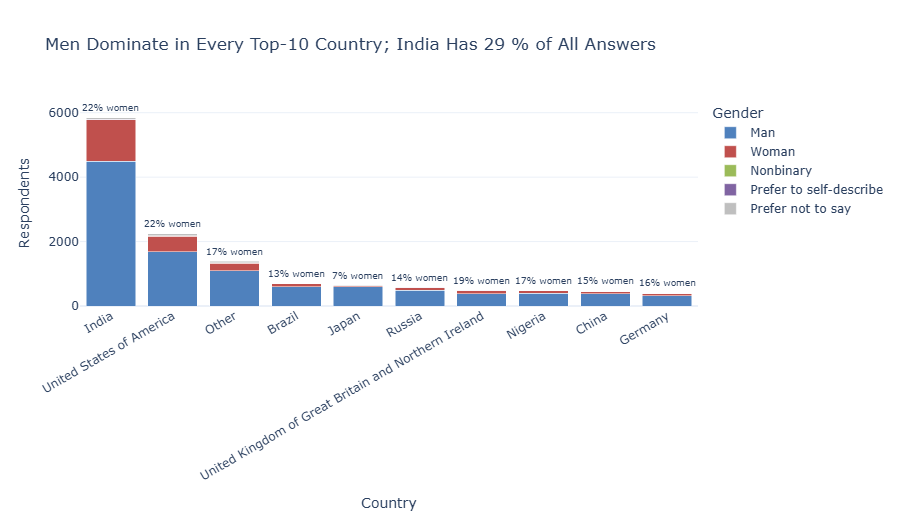

In [10]:
# --- Plot 2a ---
# Top 10 countries by total respondents, coloured by gender
gender_counts = (
    df_top10.groupby(["county_residence", "gender"]).size().reset_index(name="count")
)

# Share of women per country, to print on the chart
women_share = (df_top10["gender"] == "Woman").groupby(df_top10["county_residence"]).mean() * 100
print(women_share.sort_values(ascending=False).round(1))

fig = px.bar(
    gender_counts,
    x="county_residence",
    y="count",
    color="gender",
    barmode="stack",  # each bar = the country's total, split by gender
    category_orders={
        "county_residence": top_10_countries,  # keep the ranking order
        "gender": ["Man", "Woman", "Nonbinary", "Prefer to self-describe", "Prefer not to say"],
    },
    color_discrete_sequence=["#4F81BD", "#C0504D", "#9BBB59", "#8064A2", "#BFBFBF"],
    title="Men Dominate in Every Top-10 Country; India Has 29 % of All Answers",
    labels={"county_residence": "Country", "count": "Respondents", "gender": "Gender"},
    template="plotly_white",
    width=900,
    height=520,
)
# Write the women's share above every bar
for country in top_10_countries:
    total = (df_top10["county_residence"] == country).sum()
    fig.add_annotation(x=country, y=total, text=f"{women_share[country]:.0f}% women",
                       showarrow=False, yshift=10, font_size=9)
fig.update_layout(xaxis_tickangle=-30)
fig.show()

**What it shows:** India alone gives 5,851 of the 20,036 answers (29 %), more than twice the USA. In every country men are the large majority; women are between about 7 % (Japan) and 22 % (India). "Other" is not a country: it is the survey's group for many small countries.

                                             country  women
0                                              India   1289
1                           United States of America    483
2                                              Other    241
3                                             Brazil     93
4  United Kingdom of Great Britain and Northern I...     91
5                                             Turkey     87
6                                            Nigeria     81
7                                             Russia     80
8                                          Indonesia     79
9                                             Canada     71


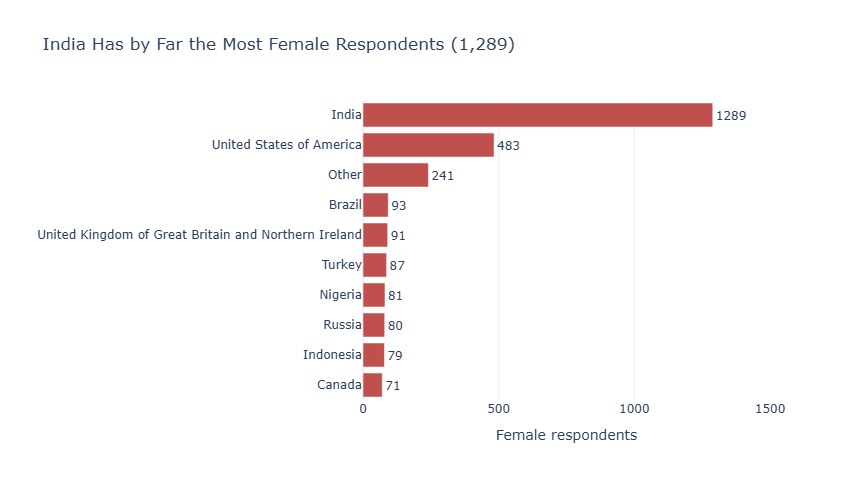

In [11]:
# --- Plot 2b ---
# Top 10 countries with the most female survey participants
# Hint: filter df for gender == 'Woman', then count by country
women = df[df["gender"] == "Woman"]
top_women = women["county_residence"].value_counts().head(10).reset_index()
top_women.columns = ["country", "women"]
print(top_women)

fig = px.bar(
    top_women,
    x="women",
    y="country",
    orientation="h",  # horizontal: long country names stay readable
    text="women",  # print the number on each bar
    title="India Has by Far the Most Female Respondents (1,289)",
    labels={"women": "Female respondents", "country": ""},
    template="plotly_white",
    width=850,
    height=480,
)
fig.update_traces(marker_color="#C0504D", textposition="outside")
fig.update_layout(yaxis={"categoryorder": "total ascending"})  # biggest bar on top
fig.update_xaxes(range=[0, 1500])  # room for the number on the longest bar
fig.show()

**What it shows:** India (1,289 women) and the USA (483) lead by far. Note that this top 10 is not the same as the overall top 10: Turkey, Indonesia and Canada enter, while Japan, China and Germany drop out. Counts follow the size of each country's survey group, so Plot 2a's shares tell the fairer story.

---

## Challenge 3: Recommended Programming Languages

**Stakeholder question**: *"Python is clearly recommended most. What is the second most recommended language? And does the answer change depending on whether the respondent is a Data Scientist, Data Analyst, or Data Engineer?"*

**Approach**:
1. First, find the overall ranking (all respondents, excluding Python)

2. Then, compare the rankings across the three job roles side by side

**Chart type suggestions**:
- A horizontal bar chart (or Plotly bar) for the overall ranking

- A grouped bar or faceted chart for the job-role comparison

**Hint**: `df[df['programming_language_recommended'] != 'Python']` filters out Python.

In [12]:
# --- Starter code: overall language recommendations (excluding Python) ---
no_python = df[df["programming_language_recommended"] != "Python"].copy()
lang_counts = no_python["programming_language_recommended"].value_counts().reset_index()
lang_counts.columns = ["language", "count"]
print(lang_counts.head(10))

     language  count
0           R   1259
1         SQL    849
2         C++    325
3           C    301
4      MATLAB    195
5        Java    167
6       Other    151
7       Julia    121
8  Javascript     88
9        Bash     26


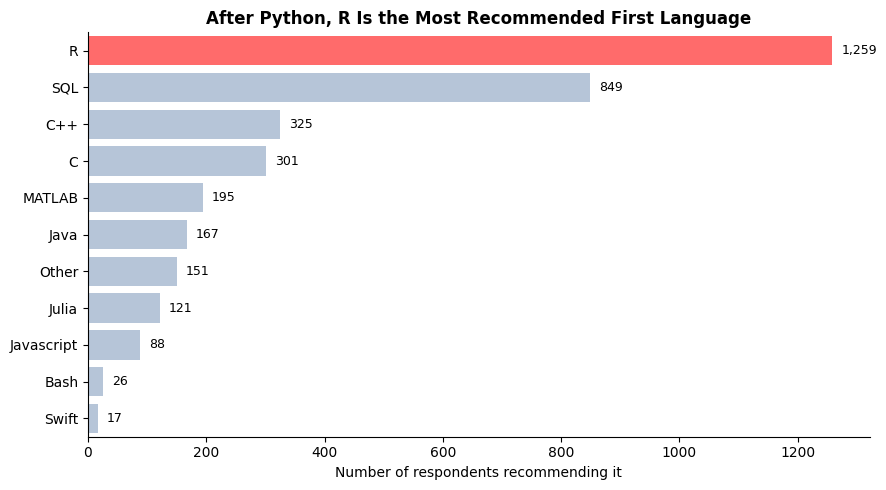

In [13]:
# --- Plot 3a: overall recommended language (excluding Python) ---
# Seaborn horizontal bar: long names are easy to read on the y-axis
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=lang_counts,
    x="count",
    y="language",
    color="#B0C4DE",  # one calm colour for all bars...
    ax=ax,
)
ax.patches[0].set_facecolor("#FF6B6B")  # ...and one highlight colour for the winner (R)

# Write the count at the end of every bar
for bar in ax.patches:
    ax.text(bar.get_width() + 15, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():,.0f}", va="center", fontsize=9)

ax.set_title("After Python, R Is the Most Recommended First Language", fontweight="bold")
ax.set_xlabel("Number of respondents recommending it")
ax.set_ylabel("")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What it shows:** R is the clear #2 (1,259 people), SQL is #3 (849), and everything else is far behind. `value_counts()` already sorts from largest to smallest, so the bars come out ranked. Python itself was recommended by 14,241 people, more than all other languages together.

latest_job_role
Data Scientist    516
Data Analyst      371
Data Engineer      81
Name: count, dtype: int64
latest_job_role                   Data Analyst  Data Engineer  Data Scientist
programming_language_recommended                                             
R                                         36.7           18.5            42.1
SQL                                       45.0           40.7            36.2
C++                                        3.5            8.6             3.9
C                                          3.5            7.4             3.3
MATLAB                                     2.7            3.7             2.5
Java                                       2.2            3.7             2.7


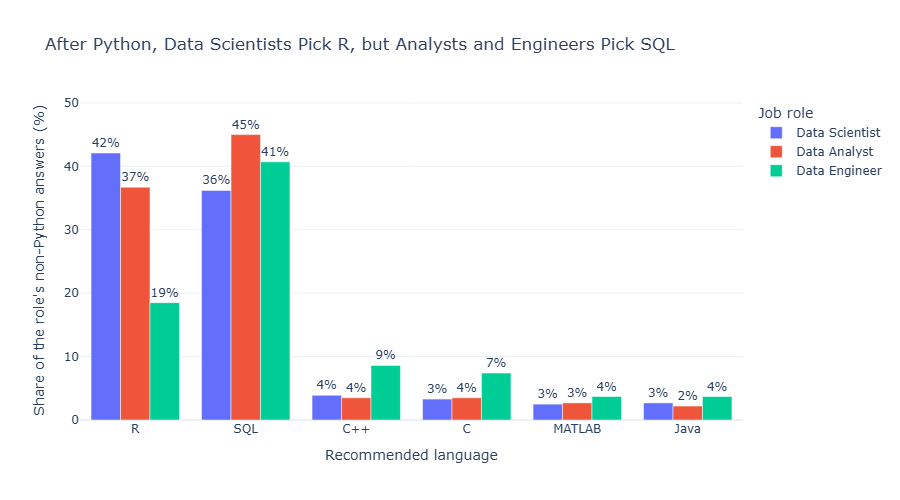

In [14]:
# --- Plot 3b: recommended language by job role (Data Scientist / Analyst / Engineer) ---
# Hint: filter to the three roles, then group by role and language
three_roles = ["Data Scientist", "Data Analyst", "Data Engineer"]
df_roles = df[
    (df["latest_job_role"].isin(three_roles))
    & (df["programming_language_recommended"] != "Python")
].copy()

# Careful: "!= 'Python'" also keeps EMPTY answers (NaN). Drop them.
df_roles = df_roles.dropna(subset=["programming_language_recommended"])

# The three roles have very different sizes, so we compare SHARES, not counts:
# what % of each role's (non-Python) answers go to each language?
role_lang = (
    df_roles.groupby("latest_job_role")["programming_language_recommended"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
    .reset_index(name="share")
)
print(df_roles["latest_job_role"].value_counts())  # how many answers per role

# Keep the six most recommended languages overall, in that order
top6 = lang_counts["language"].head(6).tolist()
role_lang = role_lang[role_lang["programming_language_recommended"].isin(top6)]
print(role_lang.pivot(index="programming_language_recommended", columns="latest_job_role", values="share").loc[top6])

fig = px.bar(
    role_lang,
    x="programming_language_recommended",
    y="share",
    color="latest_job_role",
    barmode="group",  # roles side by side for each language
    category_orders={"programming_language_recommended": top6, "latest_job_role": three_roles},
    text="share",
    title="After Python, Data Scientists Pick R, but Analysts and Engineers Pick SQL",
    labels={
        "programming_language_recommended": "Recommended language",
        "share": "Share of the role's non-Python answers (%)",
        "latest_job_role": "Job role",
    },
    template="plotly_white",
    width=900,
    height=500,
)
fig.update_traces(texttemplate="%{text:.0f}%", textposition="outside")
fig.show()

**What it shows:** we compare *shares* because the roles have very different sizes (516 Data Scientists vs 81 Data Engineers in this filtered data). Data Scientists put R first (about 42 %), while Data Analysts (about 45 %) and Data Engineers (about 41 %) put SQL first. That fits their work: analysts and engineers query databases all day.

---

## Checkpoint C: Interpreting Your Results

Answer these after completing Challenges 1–3:

1. **Challenge 1**: Which job role has the widest salary range? What does that tell you about the role?

2. **Challenge 2**: Which country has the highest proportion of female respondents in the top 10?

3. **Challenge 3**: What is the #2 recommended language overall (after Python)? Does this change significantly between roles?

4. Looking at your three plots, did you use all three libraries at least once? If not, which challenge could you redo with a different library?


**My answers** (numbers from the cells above)

1. **Widest salary range:** all three roles run from 0 to the top band (500,000 USD), so the full range is the same. The middle 50 % of salaries (the box, called IQR) is widest for **Data Scientists: about 77,000 USD**, then Data Engineers about 65,000 and Data Analysts about 39,000. The title "Data Scientist" covers everyone from juniors in low-income countries to senior specialists in the USA.
2. **Highest share of women in the top 10:** **India, about 22 %**, just ahead of the USA at about 21.6 %. Japan has the lowest share (about 6.6 %). Careful: "Other" in the top 10 is not a country, it groups many small countries.
3. **#2 language after Python:** overall it is **R** (1,259 recommendations), then SQL (849). It changes by role: Data Scientists keep R second, but **Data Analysts and Data Engineers put SQL second**. The Data Engineer group is small (81 non-Python answers), so treat that result with care.
4. **All three libraries?** Yes: Seaborn (Challenge 1, Plot 3a), Plotly (Plots 2a, 2b, 3b) and Matplotlib (Challenge 4).

---

## Challenge 4: Your Own Finding (Open-Ended)

You have now explored three specific questions. Now it is your turn to **ask a question** and answer it visually.

Browse the column list at the top of this notebook and find something interesting or unexpected. Some ideas to get you started:

- Is there a relationship between `years_of_programming` and `yearly_earnings`?

- How does `primary_tool_data_analysis` vary by `highest_education`?

- What is the age distribution of respondents from different countries?

- How does company size (`size_of_company`) correlate with ML adoption (`employer_incorporate_ml`)?

**Requirements**:

- Write a one-sentence hypothesis before you plot

- Create at least one visualization that tests or illustrates your hypothesis

- Write a one-sentence conclusion after you plot

- Use a library you have not used yet in this notebook

People used: 9,542
stage                     No ML  Exploring  Insights only  \
size_of_company                                             
0-49 employees             28.0       32.1           13.4   
50-249 employees           28.7       22.8           12.7   
250-999 employees          25.5       23.1           13.5   
1000-9,999 employees       20.8       20.4           13.8   
10,000 or more employees   10.9       17.1           12.0   

stage                     In production < 2 years  In production > 2 years  
size_of_company                                                             
0-49 employees                               16.1                     10.3  
50-249 employees                             19.1                     16.7  
250-999 employees                            19.0                     18.9  
1000-9,999 employees                         21.9                     23.0  
10,000 or more employees                     21.0                     39.0  


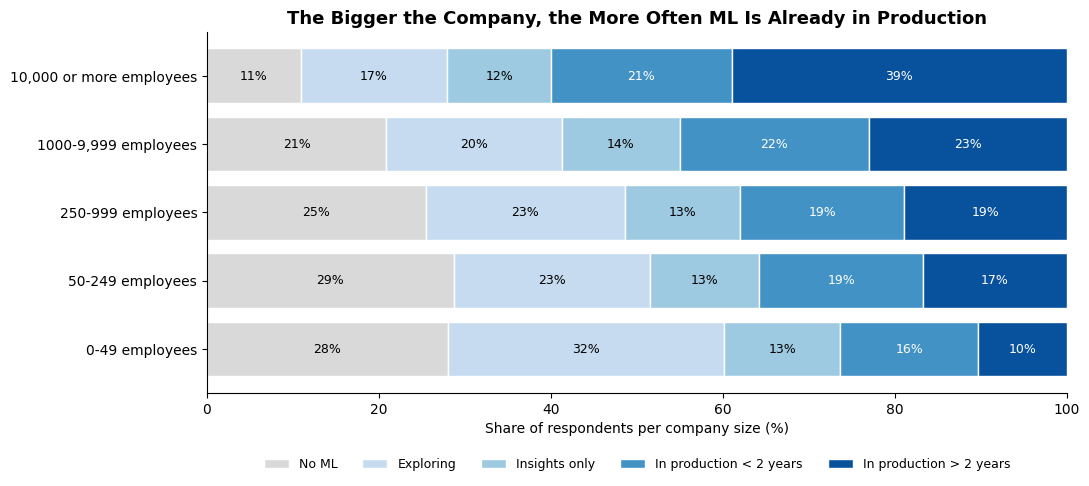

In [15]:
# My hypothesis: the bigger the company, the more often it already has
# machine learning models in production for more than 2 years.

# --- Prepare: keep people who answered both questions ---
sizes = [
    "0-49 employees",
    "50-249 employees",
    "250-999 employees",
    "1000-9,999 employees",
    "10,000 or more employees",
]
ml = df.dropna(subset=["size_of_company", "employer_incorporate_ml"])
ml = ml[ml["employer_incorporate_ml"] != "I do not know"]  # no information

# Short names for the five long answer texts (order: least to most ML)
short = {
    "No (we do not use ML methods)": "No ML",
    "We are exploring ML methods (and may one day put a model into production)": "Exploring",
    "We use ML methods for generating insights (but do not put working models into production)": "Insights only",
    "We recently started using ML methods (i.e., models in production for less than 2 years)": "In production < 2 years",
    "We have well established ML methods (i.e., models in production for more than 2 years)": "In production > 2 years",
}
ml = ml.assign(stage=ml["employer_incorporate_ml"].map(short))

# Share (%) of each answer within each company size: every row adds up to 100
share = pd.crosstab(ml["size_of_company"], ml["stage"], normalize="index") * 100
share = share.loc[sizes, list(short.values())]
print(f"People used: {len(ml):,}")
print(share.round(1))

# --- Plot: 100 % stacked horizontal bars, pure Matplotlib ---
colours = ["#d9d9d9", "#c6dbef", "#9ecae1", "#4292c6", "#08519c"]  # grey, then light to dark blue
fig, ax = plt.subplots(figsize=(11, 5))
left = [0] * len(sizes)
for stage, colour in zip(share.columns, colours):
    values = share[stage].values
    ax.barh(share.index, values, left=left, color=colour, edgecolor="white", label=stage)
    # write the % inside every segment that is wide enough
    for y, (x0, v) in enumerate(zip(left, values)):
        if v >= 8:
            text_colour = "white" if colour in ["#4292c6", "#08519c"] else "black"
            ax.text(x0 + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=9, color=text_colour)
    left = [a + b for a, b in zip(left, values)]

ax.set_title(
    "The Bigger the Company, the More Often ML Is Already in Production",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Share of respondents per company size (%)")
ax.set_xlim(0, 100)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

**My conclusion**: the hypothesis holds: "ML in production for more than 2 years" grows from about 10 % at companies with 0-49 employees to about 39 % at companies with 10,000+ employees, while "No ML" falls from about 28 % to about 11 %. (This is a survey of Kaggle users, so it shows a pattern among them, not proof for all companies.)

---

## Final Checkpoint: Explanatory vs Exploratory

Look back at all your plots in this notebook.

1. Which of your plots is the most **explanatory** (polished, clear message, ready for a stakeholder)?
   What would you change to make it presentation-ready?

2. Which of your plots is the most **exploratory** (rough but revealed a discovery)?

3. For each plot, note which library you used. Did you naturally choose different libraries for different tasks? If so, what drove those choices?

4. If you had to deliver these findings to a non-technical manager in 5 minutes, which **three** plots would you show?

> **Great work!** You have now applied data visualization to a real-world survey dataset across three different Python libraries. Review [1_Exploratory_vs_explanatory_viz.md](1_Exploratory_vs_explanatory_viz) to revisit the principles behind when and how to communicate your findings and check out [5_Fantastic_charts](5_Fantastic_charts.ipynb).

**My answers**

1. **Most explanatory:** the Challenge 1 salary box plot. Its title states the finding, the axis has the unit, and the roles are in a clear order. To make it presentation-ready I would add a source line ("Kaggle Data Science Survey 2020"), say in a footnote that salaries are the lower bound of a pay band, and use a colour-blind-safe palette.
2. **Most exploratory:** Plot 3b (language share by role). It is busy, but it revealed the real discovery: SQL beats R as the #2 language for Data Analysts and Data Engineers.
3. **Libraries:** Seaborn for the statistical box plot and the quick ranking (Challenge 1, Plot 3a); Plotly where hovering over exact counts helps (Plots 2a, 2b, 3b); Matplotlib for the custom 100 % stacked bar in Challenge 4, where I wanted full control over every bar and label. What drove the choice: statistics -> Seaborn, interaction -> Plotly, control -> Matplotlib.
4. **Five minutes with a manager:** (1) the salary box plot, (2) Plot 3b cut down to R vs SQL, (3) the company size vs ML adoption chart from Challenge 4. Each answers one question in one look.